# Logistic Regression on student dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## Load the Dataset

In [2]:
data=pd.read_csv(r'C:\Users\GAURAV SARKAR\Logistic Regression Mini Project\Data\student_data.csv')
data

,study_hours,attendance,previous_score,assignments_completed,pass
0,7,72,32,10,0
1,4,80,68,5,0
2,5,88,35,2,0
3,7,64,37,3,0
4,3,90,56,2,0
...,...,...,...,...,...
95,6,87,71,2,0
96,2,55,64,10,0
97,4,81,36,7,0
98,6,67,45,8,0


## Understand the dataset

In [3]:
data.head()

,study_hours,attendance,previous_score,assignments_completed,pass
0,7,72,32,10,0
1,4,80,68,5,0
2,5,88,35,2,0
3,7,64,37,3,0
4,3,90,56,2,0


In [4]:
data.shape

(100, 5)

In [5]:
data.columns

Index(['study_hours', 'attendance', 'previous_score', 'assignments_completed',
       'pass'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   study_hours            100 non-null    int64
 1   attendance             100 non-null    int64
 2   previous_score         100 non-null    int64
 3   assignments_completed  100 non-null    int64
 4   pass                   100 non-null    int64
dtypes: int64(5)
memory usage: 4.0 KB


In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data.rename(columns={'pass': 'pass_fail'}, inplace = True)
data.columns

Index(['study_hours', 'attendance', 'previous_score', 'assignments_completed',
       'pass_fail'],
      dtype='object')

## Exploratory Data Analysis

### Pass/Fail count

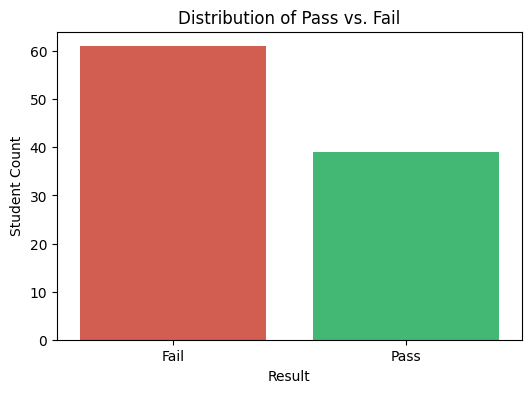

In [9]:
# Map 0 and 1 to human-readable labels
data['Result'] = data['pass_fail'].map({0: 'Fail', 1: 'Pass'})

# Plot with clear category names
plt.figure(figsize=(6, 4))
sns.countplot(
    x='Result', 
    hue='Result', 
    data=data, 
    palette={'Fail': '#e74c3c', 'Pass': '#2ecc71'}, # Red for Fail, Green for Pass
)

plt.title('Distribution of Pass vs. Fail')
plt.xlabel('Result')
plt.ylabel('Student Count')
plt.show()

### Study Hours vs Pass/Fail.

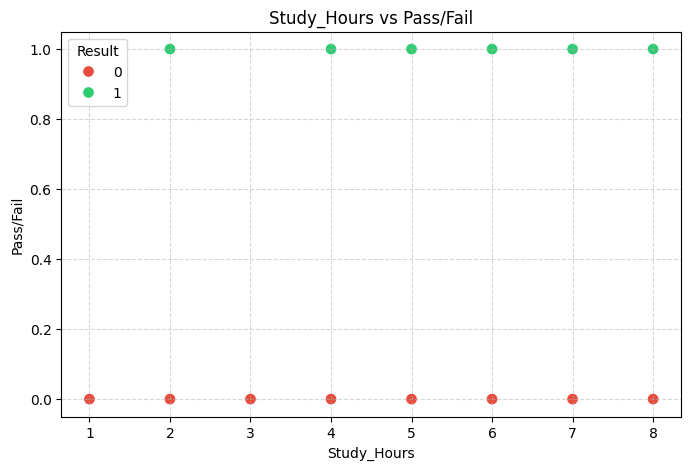

In [10]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x='study_hours',
    y='pass_fail',
    hue='pass_fail',
    palette={0: '#e74c3c',1: '#2ecc71'},   # Red for Fail (0), Green for Pass (1)
    data=data,
    s=70
)

plt.title('Study_Hours vs Pass/Fail')
plt.xlabel('Study_Hours')
plt.ylabel('Pass/Fail')
plt.legend(title='Result')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Attendence vs Pass/Fail

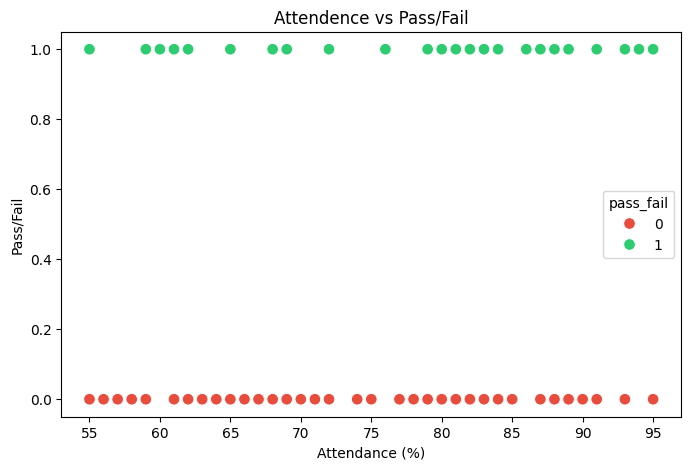

In [11]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='attendance',
    y='pass_fail',
    hue='pass_fail',
    palette={0: '#e74c3c',1: '#2ecc71'},   # Red for Fail (0), Green for Pass (1)
    s=70,
    data=data 
)

plt.title('Attendence vs Pass/Fail')
plt.xlabel('Attendance (%)')
plt.ylabel('Pass/Fail')

plt.show()

## Previous Score vs Pass/Fail

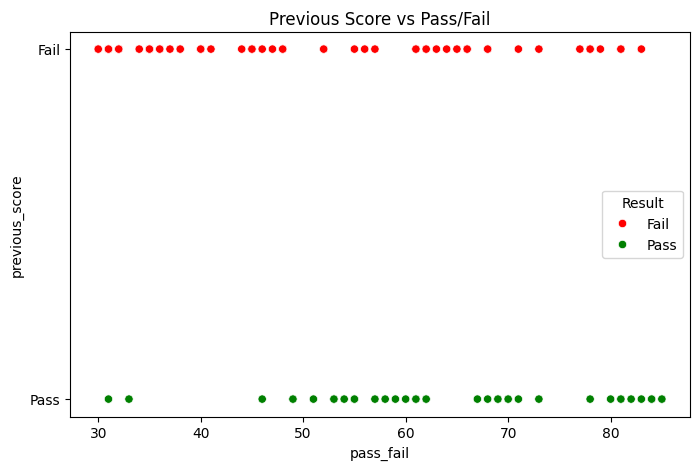

In [12]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='previous_score',
    y='Result',
    hue='Result',
    palette={"Fail": "red", "Pass": "green"},
    data=data
)
plt.title('Previous Score vs Pass/Fail')
plt.xlabel('pass_fail')
plt.ylabel('previous_score')

plt.show()

## Define Independent and Dependent Variables

In [24]:
X=data[
    ['study_hours', 
     'attendance',
     'previous_score',
     'assignments_completed'   
    ]
]
y=data['pass_fail']

## Split the Dataset

In [25]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0
)

## Creating the Logistic Regression Model

In [26]:
logreg=LogisticRegression()

## Train the Model

In [27]:
logreg.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Making Predictions

In [28]:
y_pred = logreg.predict(X_test)

## Evaluate the Model

In [29]:
accuracy=accuracy_score(y_test,y_pred)
print('Logistic Regression Accuracy: {:.3f}'.format(accuracy))

Logistic Regression Accuracy: 0.767
